 <center>
    <h1>Adult Census Income Prediction</h2>
 </center>

<h4><span style ="color:Darkblue;">
If you find this notebook valuable, please do upvote. It means a lot and will encourage me to make new notebooks like this.
</span></h4>

<h4>Data Background - </h4>This data was extracted from the **1994 Census bureau** database by Ronny Kohavi and Barry Becker (data Mining and Visualization, Silicon Graphics). *In 2016, Ronny Kohavi was named the 5th most influential scholar in AI and the 26th most influential scholar in Machine Learning.*

<h4>Task - </h4>The prediction task is to determine whether a person makes over $50K a year.
Given that the class imbalance is not severe and that both class labels are equally important, it is common to use classification accuracy or classification error to report model performance on this dataset.

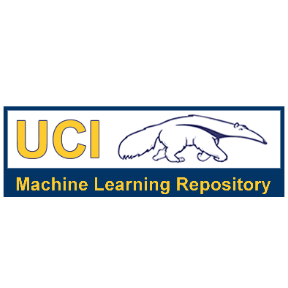

<h4>Parameters - </h4>

* age: the age of an individual
* workclass: a general term to represent the employment status of an individual
* fnlwgt: final weight. This is the number of people the census believes the entry represents..
* education: the highest level of education achieved by an individual.
* education­num: the highest level of education achieved in numerical form.
* marital­status: marital status of an individual.
* occupation: the general type of occupation of an individual
* relationship: represents what this individual is relative to others.
* race: Descriptions of an individual’s race
* sex: the sex of the individual
* capital­gain: capital gains for an individual
* capital­loss: capital loss for an individual
* hours­per­week: the hours an individual has reported to work per week
* native­country: country of origin for an individual


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler

In [ ]:
data = pd.read_csv("adult_income_dataset.csv")
data

In [ ]:
# Represents the number of rows and columns respectively.
data.shape

In [ ]:
[(col, data[col].nunique(), data[col].dtype) for col in data.columns]

In [ ]:
# fnlwgt contains very high percentage of unique values. Rest of them seems fine.
data['fnlwgt'].nunique()/data.shape[0]*100

<h4><span style ="color:Darkblue;">Insights</span></h4>

<span style ="color:steelblue;">More than half the values are unique. This probably doesn't give a sigificant information about the data. But, later in feature engineering we will see if this feature holds any importance towards our goal.</span>

In [ ]:
data.describe()

<h4><span style ="color:Darkblue;">Insights</span></h4>

<span style = 'color:steelblue'> Count tell us if there's a missing data or not. All the numerical columns seems to have no missing data here. The mean and median tell us about the skewness in the data. For capital gain and capital loss, we can see that mean > median which happens when our data is right skewed. Rest of the columns seems fine. We can also say that our capital gain and capital loss are affected by outliers. 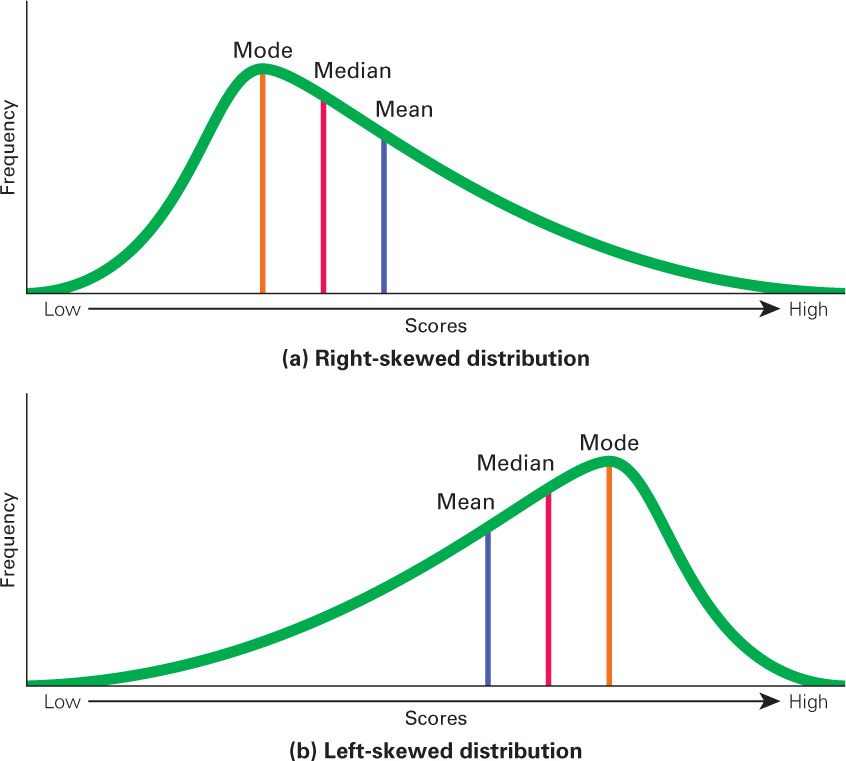 </span>

### Numerical Variables EDA

#### AGE

In [ ]:
sns.distplot(x=data['age'], axlabel='Age', color='darkblue')

In [ ]:
# We should make groups of age such that each group contains significant amount of 
# information.

print(len(data[(data['age'] > 16) & (data['age'] <= 25)]))
print(len(data[(data['age'] > 25) & (data['age'] <= 32)]))
print(len(data[(data['age'] > 32) & (data['age'] <= 40)]))
print(len(data[(data['age'] > 40) & (data['age'] <= 50)]))
print(len(data[(data['age'] > 50)]))

#### FNLWGT (Final Weight)

In [ ]:
sns.distplot(x=data['fnlwgt'], axlabel='fnlwgt', color='darkblue');

#### Education Num

In [ ]:
sns.distplot(x = data['education.num'], axlabel='Education Number', color = 'darkblue')

#### Capital Gain

In [ ]:
sns.distplot(x = data['capital.gain'], axlabel='Capital Gain', color = 'darkblue')

#### Capital Loss

In [ ]:
sns.distplot(x = data['capital.loss'], axlabel='Capital Loss', color = 'darkblue')

<h4><span style ="color:Darkblue;">Insights</span></h4>

<span style = color:steelblue>Earlier we came to a hypothesis in describe() results, that fnlwgt, captial gain and captial loss are right-skewed. Through the graph it validates our hypothesis.</span>

#### Hours per-week

In [ ]:
sns.distplot(x = data['hours.per.week'], axlabel='Numbers of Hours per Week', color = 'darkblue')

### Specify the numerical and categorical variables

In [ ]:
numerical_var = [col for col in data.columns if data[col].dtype != object]
categorical_var = [col for col in data.columns if data[col].dtype == object]
print(numerical_var)
print(categorical_var)

<h3>Categorical Variables EDA</h3>

<h4><span style ="color:Darkblue;">Insights</span></h4>

Here we have used barplot as well as countplot. Barplot which calculates the mean of the values in the particular columns. That's why we are getting values that are between 0 and 1. Countplot shows the number of observation in a category in a column.

#### Income

In [ ]:
data['income'] = data['income'].apply(lambda x:x.replace("<=50K", "0"))
data['income'] = data['income'].apply(lambda x:x.replace(">50K", "1"))
data['income'] = data['income'].astype(int)

In [ ]:
sns.displot(x = data['income'])

In [ ]:
categorical_var

In [ ]:
[(i, data[i].unique()) for i in categorical_var]

#### Workclass

In [ ]:
sns.barplot(x = 'workclass', y = 'income', data = data)
plt.xticks(rotation = 90);

#### Education

In [ ]:
# For vertical bars categorical variables should be on xaxis.
# Hue is used to include another categorical variable in the graph.
sns.barplot(x = data['education'], y = data['income'])
plt.xticks(rotation = 90);

In [ ]:
# Not a single person attending only preschool have income >50k.
len(data[(data['education'] == 'Preschool') & (data['income'] == 1)])

#### Marital Status

<span style = color:steelblue>
Here, Married-civ-spouse = when spouse is civilian.

Married-af-spouse = when spouse is in Armed Forces.</span>

In [ ]:
sns.barplot(x = 'marital.status', y = 'income', data = data)
plt.xticks(rotation = 90);

In [ ]:
plt.figure(figsize = (14,5))

sns.countplot(x = 'marital.status', data = data);
plt.xticks(rotation = 90);

#### Relationship

In [ ]:
sns.barplot(x = 'relationship', y = 'income', data = data)
plt.xticks(rotation = 90);

In [ ]:
plt.figure(figsize = (14,5))

sns.countplot(x = 'relationship', data = data);
plt.xticks(rotation = 90);

#### Occupation

In [ ]:
sns.barplot(x = 'occupation', y = 'income', data = data)
plt.xticks(rotation = 90);

In [ ]:
plt.figure(figsize = (14,5))

sns.countplot(x = 'occupation', data = data);
plt.xticks(rotation = 90);

#### Sex

In [ ]:
sns.set(style = 'darkgrid', font_scale = 1)
sns.barplot(x = 'sex', y = 'income', data = data)

In [ ]:
sns.set(style = 'darkgrid', font_scale = 1.5)
sns.catplot(x = 'sex', y = 'income', data = data, kind = 'bar', col = 'race',
            height = 5, aspect = 1)

In [ ]:
plt.figure(figsize = (14,5))

sns.countplot(x = 'race', data = data);
plt.xticks(rotation = 90);

In [ ]:
data['race'] = data['race'].apply(lambda x: 'Other' if x != 'White' else x)

#### Native Country

In [ ]:
sns.set(style = 'darkgrid', font_scale = 1)
plt.figure(figsize = (14,5))
sns.barplot(x = 'native.country', y = 'income', data = data);
plt.xticks(rotation = 90);
plt.title('Country-wise Income')

In [ ]:
plt.figure(figsize = (14,5))

sns.countplot(x = 'native.country', data = data);
plt.xticks(rotation = 90);

### Feature Engineering

In [ ]:
# age
for i in data:
    data.loc[(data['age'] > 16) & (data['age'] <= 25), 'age'] = 1
    data.loc[(data['age'] > 25) & (data['age'] <= 32), 'age'] = 2
    data.loc[(data['age'] > 32) & (data['age'] <= 40), 'age'] = 3
    data.loc[(data['age'] > 40) & (data['age'] <= 50), 'age'] = 4
    data.loc[data['age'] > 50, 'age'] = 5

In [ ]:
# education
data['education'] = data['education'].apply(lambda x: 'School' if x == '11th' or x == '7th-8th' or x == '10th' 
                                              or x == '5th-6th' or x == '9th' or x == '12th' or x == '1st-4th' 
                                              or x == 'Preschool' else x)
data['education'] = data['education'].apply(lambda x: 'Associate' if x == 'Assoc-acdm' or x == 'Assoc-voc' else x)
education_map = {'School':1,
             'HS-grad':2,
             'Some-college':3,
             'Bachelors':4,
             'Prof-school':5,
             'Associate':6,
             'Masters':7,
             'Doctorate':8}
data['education'] = data['education'].map(education_map)

In [ ]:
# creating new feature
data['capital_diff'] = abs((data['capital.gain'] - data['capital.loss']))

In [ ]:
# marital status
data['marital.status'] = data['marital.status'].apply(lambda x: 'Prev-Married' if (x == 'Widowed' or x == 'Divorced' or x == 'Separated') else x)
data['marital.status'] = data['marital.status'].apply(lambda x: 'Married' if (x == 'Married-civ-spouse' or x == 'Married-spouse-absent' or x == 'Married-AF-spouse') else x)

In [ ]:
# workclass
data['workclass'] = data['workclass'].apply(lambda x: 'No income' if x == 'Never-worked' or x == 'Without-pay'
                                            else x)

In [ ]:
#Percentage of people with ? in every column.
for col in data.columns:
    print((col, len(data[data[col] == '?'])/len(data[col])*100))

In [ ]:
# Converting ? to nan
data[data == '?'] = np.nan

In [ ]:
col_with_symbol = ['workclass', 'occupation', 'native.country']

In [ ]:
# Dropping ?
# for i in col_with_symbol:
#     data = data.drop(data.loc[data[i] == '?'].index)

In [ ]:
# Imputing ? with mode
for col in col_with_symbol:
    data[col].fillna(data[col].mode()[0], inplace=True)

<h4><span style ="color:Darkblue;">Insights</span></h4>

<span style = color:steelblue>The percetage of the entries with (?) is very low as compared to the length of the data of that particular columns. As we can see that the percentage in workclass, occupation, native.country are 6%, 6%, 2% respectively. Therefore, it seems that dropping the na values should be good choice but we can't be sure. So, check the score with and without dropping the columns and go for the one which gives better result.</span>

In [ ]:
data[col_with_symbol].describe()

In [ ]:
data.columns

In [ ]:
# native country
data['native.country'] = data['native.country'].apply(lambda x: 'Other' if x != 'United-States' else x)

### Handling Skewness

In [ ]:
# handling skewness

data['capital.gain'] = np.log1p(data['capital.gain'])
data['capital.loss'] = np.log1p(data['capital.loss'])
# data['capital_diff'] = np.log1p(data['capital_diff'])
data['fnlwgt'] = 1/(data['fnlwgt'])
# data['hours.per.week'] = (data['hours.per.week']).round(decimals = 4))

In [ ]:
data.describe()

In [ ]:
data

### Correlation

In [ ]:
plt.figure(figsize = (10, 5))
# this threw an error in the original baseline because of the non-numeric columns, could be due to python version
# sns.heatmap(data.corr(), annot = True)
# FIX #1:
sns.heatmap(data.select_dtypes(include=['number']).corr(), annot=True)

<h4><span style ="color:Darkblue;">Insights</span></h4>

<span style = color:steelblue>Education and Education num are highly correlated with each other. Therefore we should drop one of them in order to significance and uniqueness of the variable. We will see which one to drop in a few mintues.<spam/>

### Splitting of the Data

In [ ]:
y = data['income']
X = data.drop('income', axis = 1)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score # added more metrics for fair comparison
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 1, test_size = 0.2) 

In [ ]:
category_var = [col for col in X.columns if X[col].dtypes == object]
category_var

In [ ]:
numeric_var = [col for col in X.columns if X[col].dtypes != object]
numeric_var

### Multi-Collinearity

<h4><span style ="color:Darkblue;">Insights</span></h4>

There is a presence of multicollinearity if the value of VIF > 10.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calc_vif(X):

    # Calculating VIF
    vif = pd.DataFrame()
    vif["variables"] = X.columns
    vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

    return(vif)

In [ ]:
dt = X[numeric_var]
calc_vif(dt)

In [ ]:
#Deleting education num
X = X.drop('education.num', axis = 1)
# X = X.drop('capital.gain', axis = 1)
numeric_var = [col for col in X.columns if X[col].dtypes != object]
numeric_var

In [ ]:
dt = X[numeric_var]
calc_vif(dt)

### Encoding and Feature Scaling

In [ ]:
import category_encoders as ce
one_hot = ce.OneHotEncoder(cols = category_var, handle_unknown = 'ignore')

# Creating dataframe for categorical variables which converted to one hot encoded variables.
X_train_one_hot = pd.DataFrame(one_hot.fit_transform(X_train))
X_test_one_hot = pd.DataFrame(one_hot.transform(X_test))


X_train_one_hot.index = X_train.index
X_test_one_hot.index = X_test.index

num_X_train = X_train[numeric_var]
num_X_test = X_test[numeric_var]

# Joining numerical and one hot encoded variables to create our final X_train and X_test.
X_train_new = pd.concat([num_X_train, X_train_one_hot], axis = 1)
X_test_new = pd.concat([num_X_test, X_test_one_hot], axis = 1)


# X_train_new = pd.concat([num_X_train])
# X_test_new = pd.concat([num_X_test])

# Scaling our records into standard range of 0 and 1.
scaler = StandardScaler()

X_train_new = scaler.fit_transform(X_train_new)
X_test_new = scaler.transform(X_test_new)

### Model Building

#### *Logistic Regression*

Logistic Regression is a classification algorithm and is widely used for binary classfication i.e; when target variable is distributed in only two classes. Though it is used for classification its name is regression because it is derived from Linear Regression.

Limitations of Linear Regression-
1. Linear Regression gives bad fit if the data is not equally distributed.
2. The outputs may exceed 0 to 1 range.

#### *Sigmoid Function*
The basic difference between between the two algorithms is that Linear regression uses linear function whereas logistic regression uses logistic function or sigmoid function. This S shaped curve takes numeric input and outputs the results in 0 and 1. We only use sigmoid function because it gives one maxima or minima value during estimation and optimization of cost function and it is a part of bigger class of algorithms known as generalized linear models.

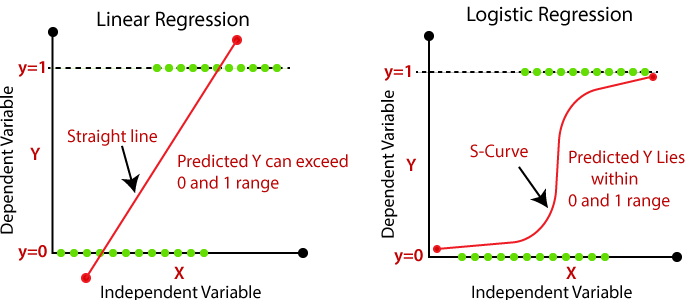

#### *Formula*: 

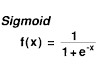

The density or probablity of y(i) given x(i) and parameterized by theta is given as:

**P(y|x;theta) = h(x)^y * (1-h(x))^1-y**

#### *Maximum Likelihood Estimation*:

Since, we know that logistic model is a probablistic model and in order to get maximum proablity of y(i) we need to optimize the above given equation. There are two ways in which we can optimize our MLE. But first, we need to understand what is MLE? MLE is known as Maximum Likelihood Estimation, it is nothing but the probablity of data. We always say Likelihood of parameters or Probablity of data. It is a process of choosing right set of paramters in such a way that it maximizes our probablity or likelihood.

There are basically two algorithms for optimization of MLE:
1. Gradient Ascent - 
2. Newton's method - (applied in very large datasets in order to get answers quickly)

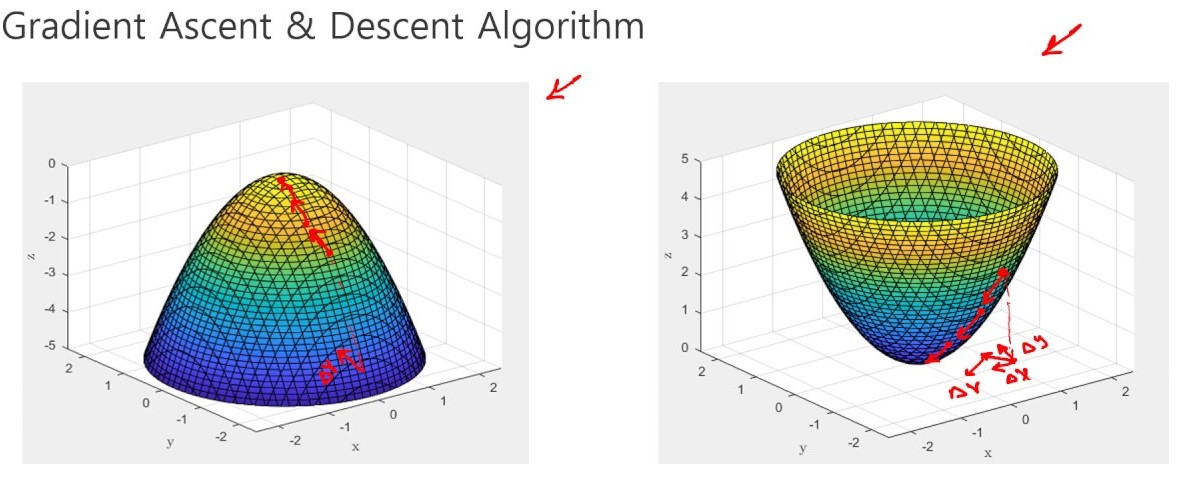

Gradient Ascent is a concave shaped graph completely opposite of gradient descent, and in this we climb up to reach to the global maxima. At that particular point we get our best result. There is no local maxima because likelihood of logistic regression is always looks like concave graph. This is also the reason why we consider only sigmoid function and not any other function that gives binary result.

In [ ]:
# Logistic Regression
model_logr = LogisticRegression(random_state = 1)
model_logr.fit(X_train_new, y_train)
pred_logr = model_logr.predict(X_test_new)
print('Accuracy Score: {0:0.3f}'. format(accuracy_score(y_test, pred_logr)))
print('Precision Score: {0:0.3f}'. format(precision_score(y_test, pred_logr)))
print('Recall Score: {0:0.3f}'. format(recall_score(y_test, pred_logr)))
print('F1 Score: {0:0.3f}'. format(f1_score(y_test, pred_logr)))
print('ROC AUC Score: {0:0.3f}'. format(roc_auc_score(y_test, model_logr.predict_proba(X_test_new)[:, 1])))

### Optimization

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

In [ ]:
LogisticRegression().get_params().keys()

In [ ]:
pipe = Pipeline([('classifier' , LogisticRegression())])
# pipe = Pipeline([('classifier', RandomForestClassifier())])

# Create param grid.

param_grid = [
    {'classifier' : [LogisticRegression()],
     'classifier__penalty' : ['l1', 'l2'],
    'classifier__C' : [0.001, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 3.0,
                       5.0, 10.0, 15.0, 20.0],
    'classifier__solver' : ['liblinear'],
    'classifier__max_iter' : [50, 100, 150, 200]}
]

# Create grid search object

clf = GridSearchCV(pipe, param_grid = param_grid, cv = 5, verbose=True, 
                   n_jobs=-1)

# Fit on data

best_clf = clf.fit(X_train_new, y_train)

In [ ]:
best_clf.best_params_

In [ ]:
# baseline never used optimized params
# model_logr = LogisticRegression(C=3.0, max_iter=50, penalty='l1', solver='liblinear')
# model_logr.fit(X_train_new, y_train)

# FIX 2:
model_logr = best_clf
pred_logr = model_logr.predict(X_test_new)

print('Accuracy Score: {0:0.3f}'. format(accuracy_score(y_test, pred_logr)))

# FIX 3: used more evaluation methods for a fairer comparison
print('Precision Score: {0:0.3f}'. format(precision_score(y_test, pred_logr)))
print('Recall Score: {0:0.3f}'. format(recall_score(y_test, pred_logr)))
print('F1 Score: {0:0.3f}'. format(f1_score(y_test, pred_logr)))
print('ROC AUC Score: {0:0.3f}'. format(roc_auc_score(y_test, model_logr.predict_proba(X_test_new)[:, 1])))

<span style = color:steelblue>The results before and after the optimization of logistic regression are similar. We didn't improve after optimization</span>

### Conclusion

In this notebook, I have tried to explain the basic flow of building a model with the help of logistic regression. Remember that while building logistic regression it is important that your data should not have multicollinearity and it is generally applicable for binary classfication.

**Thankyou!**